In [2]:
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO
from ultralytics.models.yolo.detect import DetectionPredictor
from ultralytics.utils.checks import check_imgsz


In [3]:
image_path = "/Users/tykea/Pictures/Facebookphoto.jpg"

In [4]:
model = YOLO("yolo26n.pt")
predictor = DetectionPredictor(overrides={"model": "yolo26n.pt"})
predictor.setup_model(model=model.model)

Ultralytics 8.4.216 🚀 Python-3.11.18 torch-2.14.1 CPU (Apple M3 Pro)
YOLO26n summary (fused): 120 layers, 2,408,932 parameters, 0 gradients, 5.5 GFLOPs


In [5]:
image = cv2.imread(image_path)
if image is None:
    raise FileNotFoundError(image_path)

predictor.imgsz = check_imgsz(
    predictor.args.imgsz,
    stride=predictor.model.stride,
    min_dim=2,
)

tensor = predictor.preprocess([image])

Shape: torch.Size([1, 3, 640, 640])
Data type: torch.float32
Value range: 0.0 to 1.0
Pixel values: tensor([[[[0.4471, 0.4471, 0.4471,  ..., 0.4471, 0.4471, 0.4471],
          [0.4471, 0.4471, 0.4471,  ..., 0.4471, 0.4471, 0.4471],
          [0.4471, 0.4471, 0.4471,  ..., 0.4471, 0.4471, 0.4471],
          ...,
          [0.4471, 0.4471, 0.4471,  ..., 0.4471, 0.4471, 0.4471],
          [0.4471, 0.4471, 0.4471,  ..., 0.4471, 0.4471, 0.4471],
          [0.4471, 0.4471, 0.4471,  ..., 0.4471, 0.4471, 0.4471]],

         [[0.4471, 0.4471, 0.4471,  ..., 0.4471, 0.4471, 0.4471],
          [0.4471, 0.4471, 0.4471,  ..., 0.4471, 0.4471, 0.4471],
          [0.4471, 0.4471, 0.4471,  ..., 0.4471, 0.4471, 0.4471],
          ...,
          [0.4471, 0.4471, 0.4471,  ..., 0.4471, 0.4471, 0.4471],
          [0.4471, 0.4471, 0.4471,  ..., 0.4471, 0.4471, 0.4471],
          [0.4471, 0.4471, 0.4471,  ..., 0.4471, 0.4471, 0.4471]],

         [[0.4471, 0.4471, 0.4471,  ..., 0.4471, 0.4471, 0.4471],
         

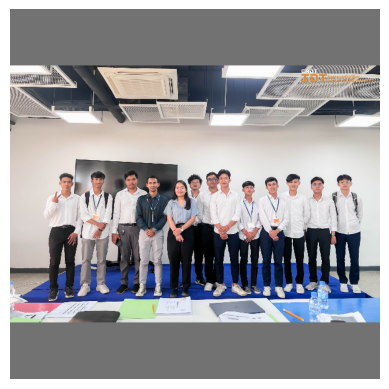

In [6]:
print("Shape:", tensor.shape)      # batch, channels, height, width
print("Data type:", tensor.dtype)
print("Value range:", tensor.min().item(), "to", tensor.max().item())
print("Pixel values:", tensor)

# Convert the tensor back into an image so you can see it
display_image = tensor[0].permute(1, 2, 0).cpu().numpy()
plt.imshow(display_image)
plt.axis("off")
plt.show()

In [13]:
import torch

net = model.model.to(tensor.device).eval()

with torch.inference_mode():
    detections, raw = net(tensor)

head = raw["one2one"]
# print(head)
print("Raw box predictions:", head["boxes"].shape)
print(head["boxes"][0, :, :5])

print("Raw class logits:", head["scores"].shape)
print(head["scores"][0, :5, :5])

Raw box predictions: torch.Size([1, 4, 8400])
tensor([[0.4826, 1.3894, 2.4035, 3.2370, 2.7051],
        [0.4959, 0.4920, 0.5199, 0.5235, 0.5142],
        [0.5222, 1.3847, 2.3575, 2.6292, 2.6107],
        [0.1093, 0.0621, 0.1774, 0.3278, 0.2566]])
Raw class logits: torch.Size([1, 80, 8400])
tensor([[-16.3590, -17.9643, -18.2587, -18.1591, -19.0071],
        [-19.0877, -20.3341, -20.7446, -20.3727, -20.9999],
        [-16.7273, -17.8677, -18.3277, -18.2560, -18.9069],
        [-18.6843, -20.3036, -20.8673, -20.5775, -21.1194],
        [-18.4394, -19.4674, -19.6906, -19.3655, -20.1380]])


In [14]:
print("Boxes:", head["boxes"].shape)
print("Scores:", head["scores"].shape)

print("Number of classes:", model.model.nc)
print("Head type:", type(model.model.model[-1]).__name__)

Boxes: torch.Size([1, 4, 8400])
Scores: torch.Size([1, 80, 8400])
Number of classes: 80
Head type: Detect
